# E-commerce Product Analytics — Engagement

## 1. Business Questions

This analysis focuses on product engagement and answers the following questions:

- How many unique users actively use the product on a daily, weekly, and monthly basis?
- How does user activity change over time?
- How sticky is the product?
- Are there noticeable changes in engagement that require further investigation?

## 2. Engagement Metrics

- **DAU (Daily Active Users)** — number of unique users who perform at least one tracked event during a day.
- **WAU (Weekly Active Users)** — number of unique users who perform at least one tracked event during a week.
- **MAU (Monthly Active Users)** — number of unique users who perform at least one tracked event during a month.
- **Stickiness (DAU/MAU)** — ratio of daily active users to monthly active users, used as an indicator of how frequently users return to the product.

Definitions follow Amplitude's product analytics materials (see References).

## 3. Data

The analysis uses the `events` table from the e-commerce dataset.

Main fields:

- `user_id` — identifies the user
- `event_time` — timestamp of the event
- `event_name` — type of event performed by the user

Only unique users are counted when calculating engagement metrics.

Only complete periods are included. The last day in the data (18 August 2025) is only partly covered, so the data end is the start of that day, and a day, week or month is included only if it ends before this point. This excludes the last day, the last week and August 2025.

The first week and month are included as the first observed periods. The first user signs up on 1 January 2023, and the first event occurs on Monday, 2 January 2023. Low values in January 2023 reflect the product launch rather than missing data.

Days without any events are kept with DAU = 0: a calendar of all days is generated and daily DAU is joined to it, so such days are not silently dropped from the series and averages. There are two such days: 1 January 2023 and 7 August 2025.

Every metric is calculated in two versions: on all events (`events`) and excluding anomalous sessions (`events_clean`). The cleaned version is the main one; the reasons are explained in Section 4. Both versions are shown on the charts.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})

# Line colors: cleaned data (main) and all data (for comparison)
CLEAN_COLOR = "tab:blue"
ALL_COLOR = "silver"


def dates_where(df, value_col, date_col, value, date_format):
    """Return all periods where the metric equals the given value, as text."""
    dates = df.loc[df[value_col] == value, date_col]
    return ", ".join(dates.dt.strftime(date_format))


def show_differences(df, date_col, value_col, date_format):
    """Show where the cleaned and all-data versions differ, with one row of context on each side."""
    differ = df[df[value_col] != df[f"{value_col}_all"]]
    first, last = differ.index.min(), differ.index.max()
    print(f"Versions differ in {len(differ)} of {len(df)} rows: "
          f"from {df.loc[first, date_col]:{date_format}} to {df.loc[last, date_col]:{date_format}}")
    rows = sorted({first - 1, first, first + 1, last - 1, last, last + 1} & set(df.index))
    display(df.loc[rows])

## 4. Data Quality: June–August 2023 Anomaly

On all data, MAU jumps about 4× in June–August 2023 (from ~125 to ~520 users) and returns to the previous level in September. The jump starts and ends exactly on month boundaries. Before treating it as growth, three checks test whether this activity comes from real users.

All queries are in `sql/01_engagement/00_data_quality.sql`.

### Check 1. Were the extra active users new customers?

If the jump came from new customers, sign-ups should grow as well. Also, a user should normally be active only after signing up.

```sql
WITH activity AS (
    SELECT
        date_trunc('month', e.event_time) AS month,
        COUNT(DISTINCT e.user_id) AS mau,
        COUNT(DISTINCT CASE WHEN e.event_time < u.signup_time
                            THEN e.user_id END) AS active_before_signup
    FROM events e
    JOIN users u
        ON e.user_id = u.user_id
    WHERE date_trunc('month', e.event_time) + INTERVAL 1 MONTH
          <= (SELECT CAST(MAX(event_time) AS DATE) FROM events)
    GROUP BY month
),

signups AS (
    SELECT
        date_trunc('month', signup_time) AS month,
        COUNT(*) AS signups
    FROM users
    GROUP BY month
)

SELECT
    a.month,
    COALESCE(s.signups, 0) AS signups,
    a.mau,
    a.active_before_signup
FROM activity a
LEFT JOIN signups s
    ON a.month = s.month
ORDER BY a.month;
```

In [2]:
activity = pd.read_csv("../data/results/01_engagement/dq_activity_vs_signups.csv")
activity["month"] = pd.to_datetime(activity["month"])

activity[(activity["month"] >= "2023-03-01") & (activity["month"] < "2023-11-01")]

,month,signups,mau,active_before_signup
2,2023-03-01,33,103,6
3,2023-04-01,24,128,4
4,2023-05-01,36,124,1
5,2023-06-01,35,518,380
6,2023-07-01,29,508,359
7,2023-08-01,43,531,360
8,2023-09-01,29,131,4
9,2023-10-01,33,131,6


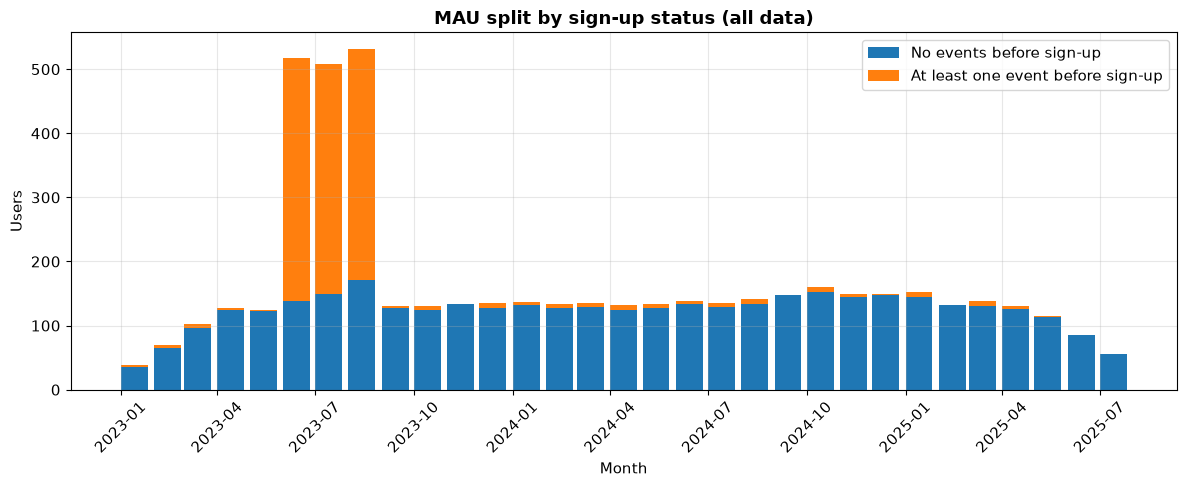

In [3]:
plt.figure(figsize=(12, 5))
plt.bar(activity["month"], activity["mau"] - activity["active_before_signup"],
        width=25, align="edge", color=CLEAN_COLOR, label="No events before sign-up")
plt.bar(activity["month"], activity["active_before_signup"],
        bottom=activity["mau"] - activity["active_before_signup"],
        width=25, align="edge", color="tab:orange", label="At least one event before sign-up")
plt.title("MAU split by sign-up status (all data)")
plt.xlabel("Month")
plt.ylabel("Users")
plt.legend(loc="upper right")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Result:** sign-ups stay at their usual level (29–43 per month), but 359–380 monthly active users have **at least one event recorded before their sign-up date**, compared with 0–9 in other months. The extra activity does not come from new customers. In this dataset, activity recorded before a user's `signup_time` is a strong data-quality signal.

### Check 2. When did these users actually sign up?

```sql
SELECT
    EXTRACT(year FROM u.signup_time) AS signup_year,
    COUNT(DISTINCT u.user_id) AS users
FROM events e
JOIN users u
    ON e.user_id = u.user_id
WHERE e.event_time >= '2023-06-01'
  AND e.event_time <  '2023-09-01'
  AND e.event_time < u.signup_time
GROUP BY signup_year
ORDER BY signup_year;
```

In [4]:
signup_year = pd.read_csv("../data/results/01_engagement/dq_signup_year.csv")
signup_year

,signup_year,users
0,2023,147
1,2024,266
2,2025,91


**Result:** of 504 users active before sign-up in June–August 2023, 357 (71%) signed up only in 2024 or 2025 — up to two years after this "activity". Activity one to two years before sign-up is unlikely to represent normal pre-registration browsing and is therefore treated as a data-quality signal.

### Check 3. What do the extra sessions look like?

**Step 1. Find the most common session profiles in June–August 2023.**

No pattern is specified in advance. Each session is turned into one row — when it started, how many events it has, and which event types it contains (sorted alphabetically, so the same set of events always gives the same string) — and the most frequent profiles are listed.

```sql
WITH sessions AS (
    SELECT
        session_id,
        MIN(event_time) AS session_start,
        COUNT(*) AS n_events,
        STRING_AGG(DISTINCT event_name, ' + ' ORDER BY event_name) AS event_types
    FROM events
    GROUP BY session_id
)

SELECT
    event_types,
    n_events,
    COUNT(*) AS sessions
FROM sessions
WHERE session_start >= '2023-06-01'
  AND session_start <  '2023-09-01'
GROUP BY
    event_types,
    n_events
ORDER BY
    sessions DESC,
    event_types
LIMIT 5;
```

In [5]:
session_profiles = pd.read_csv("../data/results/01_engagement/dq_session_profiles.csv")

# show the full event_types text instead of cutting it at 50 characters
with pd.option_context("display.max_colwidth", None):
    display(session_profiles)

,event_types,n_events,sessions
0,add_to_cart + session_end + view_product_page + website_visit,4,2165
1,checkout_complete + session_end,2,20
2,checkout_start + session_end,2,16
3,feature_click + session_end,2,16
4,search + session_end,2,15


**Result:** one profile clearly stands out — sessions containing exactly four event types, `add_to_cart`, `session_end`, `view_product_page` and `website_visit`, each occurring once, occur 2,165 times in June–August 2023, while the next most common profile occurs only 20 times. This profile is used as the pattern in the next steps.

**Step 2. Count how often this profile occurs in each month.**

The same `sessions` step is used; the final `SELECT` counts, per month, all sessions and sessions with exactly these 4 events, each occurring once. The condition `n_events = 4` is needed because `DISTINCT` in `STRING_AGG` collapses repeated events: a regular session with, for example, two `add_to_cart` events has the same set of event types but 5 events.

```sql
WITH sessions AS (
    SELECT
        session_id,
        MIN(event_time) AS session_start,
        COUNT(*) AS n_events,
        STRING_AGG(DISTINCT event_name, ' + ' ORDER BY event_name) AS event_types
    FROM events
    GROUP BY session_id
)

SELECT
    date_trunc('month', session_start) AS month,
    COUNT(*) AS all_sessions,
    COUNT(CASE WHEN n_events = 4
                AND event_types = 'add_to_cart + session_end + view_product_page + website_visit'
               THEN 1 END) AS pattern_sessions
FROM sessions
GROUP BY month
HAVING pattern_sessions > 0
ORDER BY month;
```

In [6]:
session_pattern = pd.read_csv("../data/results/01_engagement/dq_session_pattern.csv")
session_pattern["month"] = pd.to_datetime(session_pattern["month"])
session_pattern["pattern_share_pct"] = (
    session_pattern["pattern_sessions"] / session_pattern["all_sessions"] * 100
).round(2)

session_pattern

,month,all_sessions,pattern_sessions,pattern_share_pct
0,2023-06-01,1190,729,61.26
1,2023-07-01,1119,723,64.61
2,2023-08-01,1176,713,60.63
3,2023-12-01,520,1,0.19
4,2024-04-01,442,1,0.23
5,2024-06-01,448,1,0.22
6,2024-07-01,436,1,0.23
7,2025-05-01,391,1,0.26


**Result:** in June–August 2023, 61–65% of all sessions have this four-event profile (2,165 sessions in total), and none of them includes a checkout. In the other 28 months the profile occurs only 5 times.

**Step 3. Check the order and duration of these sessions.**

`STRING_AGG(... ORDER BY event_name)` in Steps 1–2 sorts event types alphabetically, so it shows which events a session contains, but not their order. Here the events of each pattern session are joined in time order (`ORDER BY event_time`), and the session duration is added.

```sql
WITH sessions AS (
    SELECT
        session_id,
        MIN(event_time) AS session_start,
        COUNT(*) AS n_events,
        STRING_AGG(DISTINCT event_name, ' + ' ORDER BY event_name) AS event_types,
        STRING_AGG(event_name, ' -> ' ORDER BY event_time) AS event_sequence,
        date_diff('second', MIN(event_time), MAX(event_time)) AS duration_sec
    FROM events
    GROUP BY session_id
)

SELECT
    event_sequence,
    duration_sec,
    COUNT(*) AS sessions
FROM sessions
WHERE n_events = 4
  AND event_types = 'add_to_cart + session_end + view_product_page + website_visit'
  AND session_start >= '2023-06-01'
  AND session_start <  '2023-09-01'
GROUP BY
    event_sequence,
    duration_sec
ORDER BY sessions DESC;
```

In [7]:
session_sequence = pd.read_csv("../data/results/01_engagement/dq_session_sequence.csv")

with pd.option_context("display.max_colwidth", None):
    display(session_sequence)

,event_sequence,duration_sec,sessions
0,website_visit -> view_product_page -> add_to_cart -> session_end,30,2165


**Result:** all 2,165 sessions are identical: they contain exactly the same four events, in the same order — `website_visit` → `view_product_page` → `add_to_cart` → `session_end` — and every session lasts exactly 30 seconds. Combined with the pre-sign-up activity and the absence of a corresponding increase in sign-ups (Checks 1–2), this is treated as a data-quality signal.

### Decision

The activity in June–August 2023 is treated as anomalous and excluded from the main metrics based on the data-quality checks above:

- **Rule:** sessions containing exactly these four event types, each occurring once, that started between 1 June and 31 August 2023 are excluded. The 5 similar sessions outside this window are kept. The order and the 30-second duration are not part of the rule; they confirm that the excluded sessions are identical.
- **How:** the table `events_clean` (`setup/01_create_events_clean.sql`) is a copy of `events` without these sessions. The `events` table itself is not changed.
- **Both versions are shown:** the charts below display the cleaned data (blue) and all data (grey), so the effect of the exclusion is visible.
- **Limitation:** the dataset is synthetic and has no traffic source, device or IP fields, so the exact cause (bots, tracking error, data generator) cannot be confirmed.

### Impact on Engagement Metrics

Average values for June–August 2023, all data vs. excluding anomalous sessions:

In [8]:
metrics = {
    "DAU": ("dau_by_day", "day", "dau"),
    "WAU": ("wau_by_week", "week", "wau"),
    "MAU": ("mau_by_month", "month", "mau"),
    "Stickiness, %": ("stickiness_pct", "month", "stickiness_pct"),
}

rows = []
for name, (file, date_col, value_col) in metrics.items():
    averages = []
    for suffix in ["", "_clean"]:
        df = pd.read_csv(f"../data/results/01_engagement/{file}{suffix}.csv", parse_dates=[date_col])
        in_window = (df[date_col] >= "2023-06-01") & (df[date_col] < "2023-09-01")
        averages.append(df.loc[in_window, value_col].mean())
    rows.append({
        "Metric": name,
        "All data": round(averages[0], 1),
        "Excluding anomalous sessions": round(averages[1], 1),
        "All / cleaned": round(averages[0] / averages[1], 2),
    })

pd.DataFrame(rows)

,Metric,All data,Excluding anomalous sessions,All / cleaned
0,DAU,74.1,52.1,1.42
1,WAU,229.2,101.1,2.27
2,MAU,519.0,129.3,4.01
3,"Stickiness, %",14.3,40.3,0.35


**Result:** the anomaly distorts all four metrics, and the longer the period, the stronger the effect: DAU is inflated 1.4×, WAU 2.3× and MAU 4×. Stickiness is the opposite — it looks almost 3 times *lower*, because MAU is inflated much more than DAU. Outside June–August 2023 both versions are identical.

## 5. DAU

### Business Question

How many unique users actively use the product each day?

### Definition

**DAU (Daily Active Users)** is the number of unique users who perform at least one tracked event during a given day.

### DAU Calculation

```sql
WITH calendar AS (
    -- all days from the start of the first month to the data end
    SELECT range AS day
    FROM range(
        (SELECT date_trunc('month', MIN(event_time)) FROM events_clean),
        (SELECT CAST(MAX(event_time) AS DATE) FROM events_clean),
        INTERVAL 1 DAY
    )
),

daily AS (
    SELECT
        date_trunc('day', event_time) AS day,
        COUNT(DISTINCT user_id) AS dau
    FROM events_clean
    GROUP BY day
)

SELECT
    c.day,
    COALESCE(d.dau, 0) AS dau
FROM calendar c
LEFT JOIN daily d
    ON c.day = d.day
ORDER BY c.day;
```

The all-data version is the same query with `FROM events` instead of `FROM events_clean`.

### Results

In [9]:
dau = pd.read_csv("../data/results/01_engagement/dau_by_day_clean.csv")
dau_all = pd.read_csv("../data/results/01_engagement/dau_by_day.csv")
dau = dau.merge(dau_all[["day", "dau"]].rename(columns={"dau": "dau_all"}), on="day")
dau["day"] = pd.to_datetime(dau["day"])

show_differences(dau, "day", "dau", "%Y-%m-%d")

Versions differ in 91 of 960 rows: from 2023-06-01 to 2023-08-30


,day,dau,dau_all
150,2023-05-31,46,46
151,2023-06-01,51,78
152,2023-06-02,51,72
240,2023-08-29,54,80
241,2023-08-30,58,75
242,2023-08-31,50,50


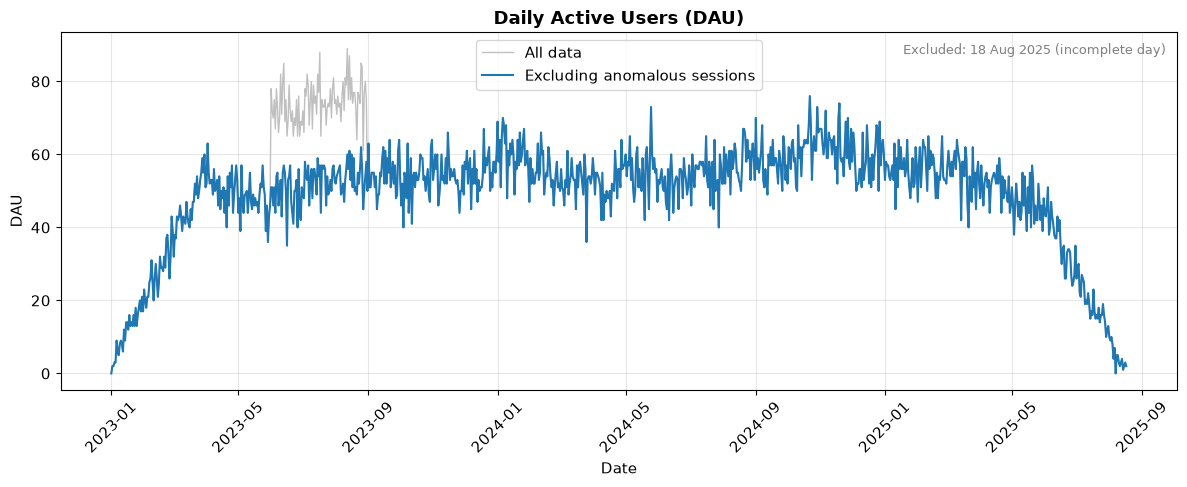

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(dau["day"], dau["dau_all"], color=ALL_COLOR, linewidth=1, label="All data")
plt.plot(dau["day"], dau["dau"], color=CLEAN_COLOR, label="Excluding anomalous sessions")
plt.title("Daily Active Users (DAU)")
plt.xlabel("Date")
plt.ylabel("DAU")
plt.legend(loc="upper center")
plt.text(0.99, 0.97, "Excluded: 18 Aug 2025 (incomplete day)",
         transform=plt.gca().transAxes, ha="right", va="top",
         fontsize=9, color="gray")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
dau_summary = pd.DataFrame({
    "Metric": ["Minimum DAU", "Maximum DAU", "Average DAU"],
    "Value": [
        dau["dau"].min(),
        dau["dau"].max(),
        round(dau["dau"].mean(), 2)
    ],
    "Date": [
        dates_where(dau, "dau", "day", dau["dau"].min(), "%Y-%m-%d"),
        dates_where(dau, "dau", "day", dau["dau"].max(), "%Y-%m-%d"),
        "—"
    ]
})

dau_summary

,Metric,Value,Date
0,Minimum DAU,0.00,"2023-01-01, 2025-08-07"
1,Maximum DAU,76.00,2024-10-22
2,Average DAU,49.49,—


### Finding

On cleaned data, DAU ranges from 0 to 76 users, with an average of 49.49. DAU is zero on two days without any events (1 January 2023 and 7 August 2025).

Daily activity grows during the first half of 2023, stays at roughly 50–60 users per day from mid-2023 to spring 2025, and declines from May 2025. The highest DAU of 76 users was recorded on 22 October 2024.

On all data (grey line), DAU is higher in June–August 2023, peaking at 89 users on 12 August 2023 — this is the effect of the anomalous sessions.

## 6. WAU

### Business Question

How many unique users actively use the product each week?

### Definition

**WAU (Weekly Active Users)** is the number of unique users who perform at least one tracked event during a given week.

### WAU Calculation

```sql
SELECT 
    date_trunc('week', event_time) AS week,
    COUNT(DISTINCT user_id) AS wau
FROM events_clean
WHERE date_trunc('week', event_time) + INTERVAL 7 DAY
      <= (SELECT CAST(MAX(event_time) AS DATE) FROM events_clean)
GROUP BY week
ORDER BY week;
```

The all-data version is the same query with `FROM events` instead of `FROM events_clean`.

### Results

In [12]:
wau = pd.read_csv("../data/results/01_engagement/wau_by_week_clean.csv")
wau_all = pd.read_csv("../data/results/01_engagement/wau_by_week.csv")
wau = wau.merge(wau_all[["week", "wau"]].rename(columns={"wau": "wau_all"}), on="week")
wau["week"] = pd.to_datetime(wau["week"])

show_differences(wau, "week", "wau", "%Y-%m-%d")

Versions differ in 14 of 137 rows: from 2023-05-29 to 2023-08-28


,week,wau,wau_all
20,2023-05-22,94,94
21,2023-05-29,99,186
22,2023-06-05,96,242
33,2023-08-21,109,235
34,2023-08-28,107,175
35,2023-09-04,105,105


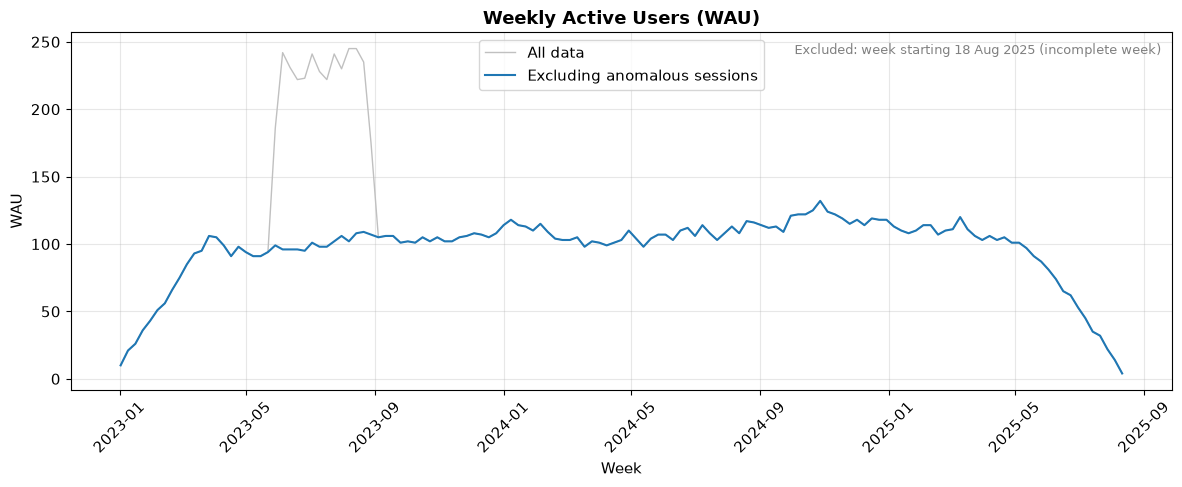

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(wau["week"], wau["wau_all"], color=ALL_COLOR, linewidth=1, label="All data")
plt.plot(wau["week"], wau["wau"], color=CLEAN_COLOR, label="Excluding anomalous sessions")
plt.title("Weekly Active Users (WAU)")
plt.xlabel("Week")
plt.ylabel("WAU")
plt.legend(loc="upper center")
plt.text(0.99, 0.97, "Excluded: week starting 18 Aug 2025 (incomplete week)",
         transform=plt.gca().transAxes, ha="right", va="top",
         fontsize=9, color="gray")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
wau_summary = pd.DataFrame({
    "Metric": ["Minimum WAU", "Maximum WAU", "Average WAU"],
    "Value": [
        wau["wau"].min(),
        wau["wau"].max(),
        round(wau["wau"].mean(), 2)
    ],
    "Week starting": [
        dates_where(wau, "wau", "week", wau["wau"].min(), "%Y-%m-%d"),
        dates_where(wau, "wau", "week", wau["wau"].max(), "%Y-%m-%d"),
        "—"
    ]
})

wau_summary

,Metric,Value,Week starting
0,Minimum WAU,4.00,2025-08-11
1,Maximum WAU,132.00,2024-10-28
2,Average WAU,97.28,—


### Finding

On cleaned data, WAU ranges from 4 to 132 users, with an average of 97.28.

From mid-2023 to spring 2025, WAU stays at roughly 95–130 users per week, with a peak of 132 users in the week starting 28 October 2024. The minimum of 4 users is in the last complete week (starting 11 August 2025), when activity is ending.

On all data (grey line), WAU reaches 245 users in August 2023 because of the anomalous sessions.

## 7. MAU

### Business Question

How many unique users actively use the product each month?

### Definition

**MAU (Monthly Active Users)** is the number of unique users who perform at least one tracked event during a given month.

### MAU Calculation

```sql
SELECT 
    date_trunc('month', event_time) AS month,
    COUNT(DISTINCT user_id) AS mau
FROM events_clean
WHERE date_trunc('month', event_time) + INTERVAL 1 MONTH
      <= (SELECT CAST(MAX(event_time) AS DATE) FROM events_clean)
GROUP BY month
ORDER BY month;
```

The all-data version is the same query with `FROM events` instead of `FROM events_clean`.

### Results

In [15]:
mau = pd.read_csv("../data/results/01_engagement/mau_by_month_clean.csv")
mau_all = pd.read_csv("../data/results/01_engagement/mau_by_month.csv")
mau = mau.merge(mau_all[["month", "mau"]].rename(columns={"mau": "mau_all"}), on="month")
mau["month"] = pd.to_datetime(mau["month"])

show_differences(mau, "month", "mau", "%Y-%m")

Versions differ in 3 of 31 rows: from 2023-06 to 2023-08


,month,mau,mau_all
4,2023-05-01,124,124
5,2023-06-01,124,518
6,2023-07-01,123,508
7,2023-08-01,141,531
8,2023-09-01,131,131


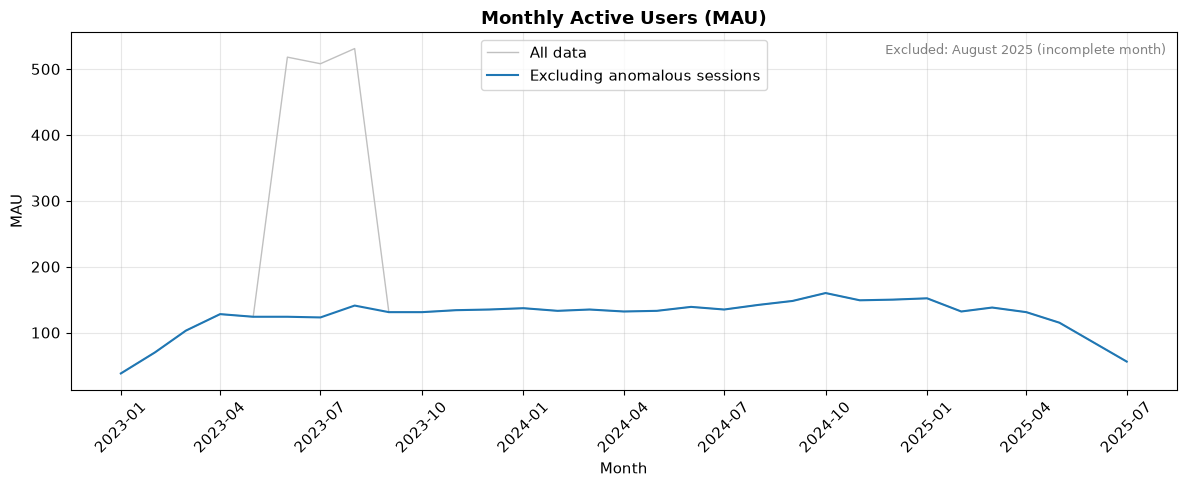

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(mau["month"], mau["mau_all"], color=ALL_COLOR, linewidth=1, label="All data")
plt.plot(mau["month"], mau["mau"], color=CLEAN_COLOR, label="Excluding anomalous sessions")
plt.title("Monthly Active Users (MAU)")
plt.xlabel("Month")
plt.ylabel("MAU")
plt.legend(loc="upper center")
plt.text(0.99, 0.97, "Excluded: August 2025 (incomplete month)",
         transform=plt.gca().transAxes, ha="right", va="top",
         fontsize=9, color="gray")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
mau_summary = pd.DataFrame({
    "Metric": ["Minimum MAU", "Maximum MAU", "Average MAU"],
    "Value": [
        mau["mau"].min(),
        mau["mau"].max(),
        round(mau["mau"].mean(), 2)
    ],
    "Month": [
        dates_where(mau, "mau", "month", mau["mau"].min(), "%B %Y"),
        dates_where(mau, "mau", "month", mau["mau"].max(), "%B %Y"),
        "—"
    ]
})

mau_summary

,Metric,Value,Month
0,Minimum MAU,38.00,January 2023
1,Maximum MAU,160.00,October 2024
2,Average MAU,125.29,—


### Finding

On cleaned data, MAU ranges from 38 to 160 users, with an average of 125.29.

MAU grows from 38 users in January 2023 to ~125 by April 2023. From September 2023 to April 2025 it is stable at 131–160 users, with a peak of 160 users in October 2024. From May 2025 MAU declines, reaching 56 users in July 2025.

On all data (grey line), MAU jumps to 508–531 users in June–August 2023; without the anomalous sessions it is 123–141 users, in line with the surrounding months.

## 8. Stickiness

### Business Question

How frequently do users return to the product?

### Definition

**Stickiness (DAU/MAU)** measures the proportion of monthly active users who are active on a typical day.

### Stickiness Calculation

Monthly stickiness is average DAU divided by MAU for each complete calendar month.

Average DAU is calculated as the sum of daily DAU divided by the number of days in the month. The sum of daily DAU equals the number of (user, active day) pairs in the month. Days without events add nothing to this sum, so dividing by the full length of the month counts them as DAU = 0 — no calendar is needed.

```sql
WITH active_user_days AS (
    -- one row per user per day with at least one event, complete months only
    SELECT DISTINCT
        user_id,
        CAST(event_time AS DATE) AS day
    FROM events_clean
    WHERE date_trunc('month', event_time) + INTERVAL 1 MONTH
          <= (SELECT CAST(MAX(event_time) AS DATE) FROM events_clean)
),

monthly AS (
    SELECT
        date_trunc('month', day) AS month,
        COUNT(*) AS dau_sum,                 -- sum of daily DAU over the month
        COUNT(DISTINCT user_id) AS mau
    FROM active_user_days
    GROUP BY month
)

SELECT
    month,
    ROUND(dau_sum * 1.0 / day(last_day(month)), 2) AS monthly_avg_dau,
    mau,
    ROUND(dau_sum * 100.0 / day(last_day(month)) / mau, 2) AS stickiness_pct
FROM monthly
ORDER BY month;
```

`day(last_day(month))` is the number of days in the month (for example, 31 for January, 29 for February 2024).

The all-data version is the same query with `FROM events` instead of `FROM events_clean`.

### Results

In [18]:
stickiness = pd.read_csv("../data/results/01_engagement/stickiness_pct_clean.csv")
stickiness_all = pd.read_csv("../data/results/01_engagement/stickiness_pct.csv")
stickiness = stickiness.merge(stickiness_all[["month", "stickiness_pct"]].rename(columns={"stickiness_pct": "stickiness_pct_all"}), on="month")
stickiness["month"] = pd.to_datetime(stickiness["month"])

show_differences(stickiness, "month", "stickiness_pct", "%Y-%m")

Versions differ in 3 of 31 rows: from 2023-06 to 2023-08


,month,monthly_avg_dau,mau,stickiness_pct,stickiness_pct_all
4,2023-05-01,47.29,124,38.14,38.14
5,2023-06-01,49.23,124,39.70,13.89
6,2023-07-01,53.03,123,43.12,14.73
7,2023-08-01,53.84,141,38.18,14.20
8,2023-09-01,54.83,131,41.86,41.86


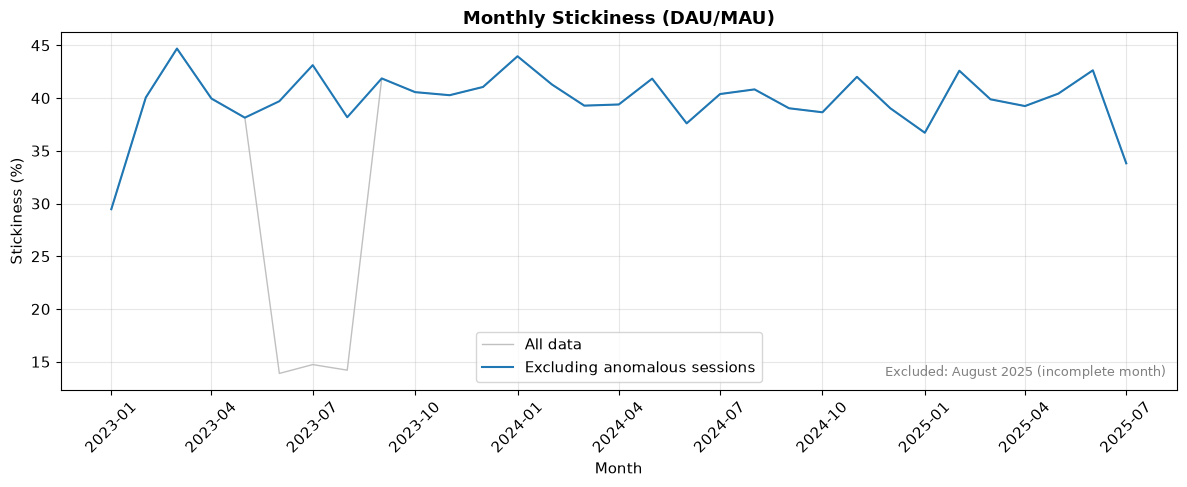

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(stickiness["month"], stickiness["stickiness_pct_all"], color=ALL_COLOR, linewidth=1, label="All data")
plt.plot(stickiness["month"], stickiness["stickiness_pct"], color=CLEAN_COLOR, label="Excluding anomalous sessions")
plt.title("Monthly Stickiness (DAU/MAU)")
plt.xlabel("Month")
plt.ylabel("Stickiness (%)")
plt.legend(loc="lower center")
plt.text(0.99, 0.03, "Excluded: August 2025 (incomplete month)",
         transform=plt.gca().transAxes, ha="right", va="bottom",
         fontsize=9, color="gray")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
stickiness_summary = pd.DataFrame({
    "Metric": ["Minimum stickiness", "Maximum stickiness", "Average stickiness"],
    "Value": [
        stickiness["stickiness_pct"].min(),
        stickiness["stickiness_pct"].max(),
        round(stickiness["stickiness_pct"].mean(), 2)
    ],
    "Month": [
        dates_where(stickiness, "stickiness_pct", "month", stickiness["stickiness_pct"].min(), "%B %Y"),
        dates_where(stickiness, "stickiness_pct", "month", stickiness["stickiness_pct"].max(), "%B %Y"),
        "—"
    ]
})

stickiness_summary

,Metric,Value,Month
0,Minimum stickiness,29.46,January 2023
1,Maximum stickiness,44.69,March 2023
2,Average stickiness,39.86,—


### Finding

On cleaned data, stickiness ranges from 29.46% (January 2023, when the audience was only forming) to 44.69% (March 2023), with an average of 39.86%.

For most of the period stickiness stays at about 37–44%, including June–August 2023: on a typical day, about two in five monthly active users use the product. It drops to 33.81% in July 2025.

Stickiness of ~40% means that an average monthly user is active on about 12 days per month. This level of engagement may reflect the synthetic nature of the dataset rather than typical e-commerce behaviour. Purchase-based metrics, such as repeat purchase behaviour, are more informative for e-commerce; purchase retention is analysed in `03_purchase_retention.ipynb`.

On all data (grey line), stickiness falls to ~14% in June–August 2023. This drop is caused by the anomaly: MAU is inflated much more than DAU.

## 9. Key Findings

- **Data quality.** The MAU spike in June–August 2023 cannot be treated as organic growth. It is driven by 2,165 identical sessions (`website_visit` → `view_product_page` → `add_to_cart` → `session_end`, no checkout), mostly attributed to users before their sign-up date, while sign-ups stayed at the usual level. These sessions are excluded from the main metrics; both versions are shown on the charts.
- **Stable audience.** After growing in the first half of 2023, MAU stays at 131–160 users from September 2023 to April 2025, with a peak of 160 in October 2024. DAU and WAU follow the same pattern (average 49.49 and 97.28 users).
- **Stable stickiness.** Stickiness stays at about 37–44% (average 39.86%): about two in five monthly users are active on a typical day. The apparent drop to ~14% in mid-2023 was caused by the anomaly.
- **Decline in 2025.** From May 2025 MAU declines to 56 users in July 2025. Stickiness stays at its usual level until June 2025 (42.63%) and drops to 33.81% only in July.

## 10. Product Interpretation

Excluding the anomaly, the engagement metrics show three periods.

**Ramp-up (January–May 2023).** The active audience grows as new users sign up.

**Stable period (September 2023–April 2025).** The product keeps a stable core of 130–160 monthly active users who return frequently: about 40% of them are active on a typical day. June–August 2023 is excluded from this description because of the data anomaly; on cleaned data, MAU in these months (123–141) is close to this level.

**Decline (May–July 2025).** The audience shrinks, but the users who remain use the product about as often as before until July. This is consistent with a decline in the number of active users rather than a comparable decline in usage frequency among the remaining users. The last recorded user sign-up is 20 May 2025, while activity continues until August 2025. This may indicate incomplete acquisition data, although the dataset alone cannot confirm this. The source repository was first published on 21 May 2025 (see README): sign-ups end at the publication date, while events after it can only come from already registered users. Further analysis would be needed to distinguish a real engagement decline from dataset truncation or incomplete acquisition data.

Without the data quality check, the report would show a 4× growth peak and a collapse of stickiness in mid-2023, both of which reflect the anomalous sessions rather than the regular user base.

## 11. Next Questions

1. What is the source of the anomalous sessions (traffic source, device, IP)? These fields are not available in this dataset.
2. How does retention differ across sign-up cohorts?
3. Which user cohorts and acquisition channels have the highest and lowest stickiness?
4. Why do sign-ups stop after 20 May 2025 — end of the dataset or a real stop in acquisition? The available data may not be enough to answer this.

## 12. Limitations

- The dataset is synthetic, and its generator is not available, so the cause of the June–August 2023 anomaly is unknown. The anomalous sessions are excluded because of their pattern, not because their source is confirmed.
- The exclusion rule removes sessions with exactly these four events, each occurring once, that started in June–August 2023; anomalous sessions of a different form would not be detected.
- The decline after May 2025 coincides with the end of sign-ups and with the publication date of the dataset, so the data cannot distinguish a real decline from dataset truncation.
- An active user is a user with any tracked event, including technical events such as `session_end`; a narrower definition of activity could give lower DAU, WAU and MAU.
- The analysis is observational and does not establish causal relationships.

## 13. References

Metric definitions follow Amplitude's product analytics materials:

- Amplitude — [You're Measuring Daily Active Users Wrong](https://amplitude.com/blog/measuring-active-users) (DAU, MAU and DAU/MAU stickiness)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)